# Rossmann Store Sales : prévision des ventes (DuckDB, LightGBM, MLflow)

Prévoir les ventes quotidiennes des magasins Rossmann à partir de train.csv, test.csv et store.csv.



## Stockage des tables et jointure

Les CSV sont chargés dans une base DuckDB (`../rossmann.duckdb`). 

In [1]:
import duckdb

con = duckdb.connect("../rossmann.duckdb")

con.execute("""
    CREATE OR REPLACE TABLE train AS
    SELECT * FROM read_csv_auto('../data/raw/train.csv',
                                types={'StateHoliday': 'VARCHAR'})
""")
con.execute("""
    CREATE OR REPLACE TABLE store AS
    SELECT * FROM read_csv_auto('../data/raw/store.csv')
""")

In [2]:

con.sql("SELECT * FROM train LIMIT 20").show()
con.sql("SELECT * FROM store LIMIT 5").show()

┌───────┬───────────┬────────────┬───────┬───────────┬───────┬───────┬──────────────┬───────────────┐
│ Store │ DayOfWeek │    Date    │ Sales │ Customers │ Open  │ Promo │ StateHoliday │ SchoolHoliday │
│ int64 │   int64   │    date    │ int64 │   int64   │ int64 │ int64 │   varchar    │     int64     │
├───────┼───────────┼────────────┼───────┼───────────┼───────┼───────┼──────────────┼───────────────┤
│     1 │         5 │ 2015-07-31 │  5263 │       555 │     1 │     1 │ 0            │             1 │
│     2 │         5 │ 2015-07-31 │  6064 │       625 │     1 │     1 │ 0            │             1 │
│     3 │         5 │ 2015-07-31 │  8314 │       821 │     1 │     1 │ 0            │             1 │
│     4 │         5 │ 2015-07-31 │ 13995 │      1498 │     1 │     1 │ 0            │             1 │
│     5 │         5 │ 2015-07-31 │  4822 │       559 │     1 │     1 │ 0            │             1 │
│     6 │         5 │ 2015-07-31 │  5651 │       589 │     1 │     1 │ 0          

### Récupération des tables

In [3]:
train = con.execute("SELECT * FROM train").df()
store = con.execute("SELECT * FROM store").df()

In [4]:
print("--- store ---")
print(store.isna().sum())
print("--- train ---")
print(train.isna().sum())

--- store ---
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64
--- train ---
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64


### Jointure entre `train` et `store` pour enrichir les données

In [5]:
df = con.execute("""
    SELECT t.*, s.* EXCLUDE (Store)
    FROM train t
    LEFT JOIN store s ON t.store = s.store
""").df()

print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270,9,2008,0,<NA>,<NA>,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570,11,2007,1,13,2010,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130,12,2006,1,14,2011,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620,9,2009,0,<NA>,<NA>,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910,4,2015,0,<NA>,<NA>,NaN


In [6]:
# la jointure ne doit ni ajouter ni perdre de lignes
print(len(train), len(df))
df.isna().sum()

1017209 1017209


Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

## Nettoyage

Supprimer les lignes où le magasin est ouvert (`Open = 1`) mais où les ventes sont nulles (`Sales = 0`). Les jours fermés sont aussi exclus de l'entraînement.

In [7]:
df_model = df[(df["Open"] == 1) & (df["Sales"] > 0)].copy()

print(len(df), "->", len(df_model), "lignes")

1017209 -> 844338 lignes


## Exploration et contrôles

### Matrice de corrélation

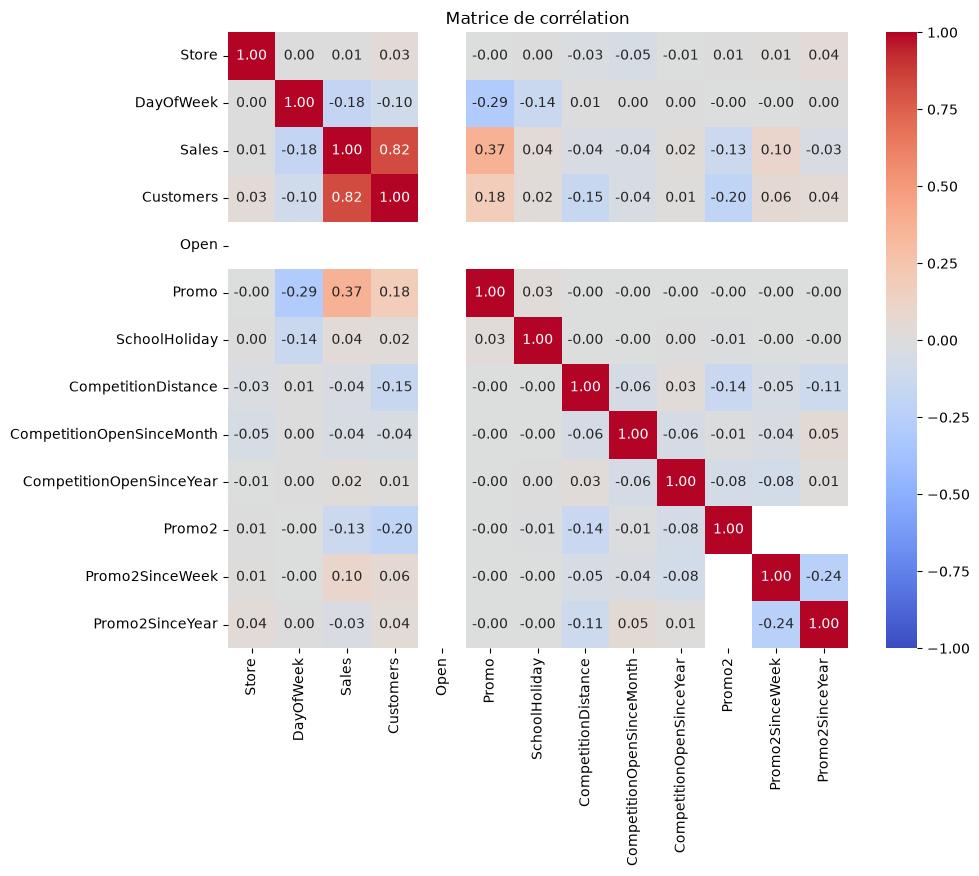

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_model.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

### Doublons

In [9]:
# Une ligne par magasin et par jour 
df_model.duplicated(subset=["Store", "Date"]).sum()

np.int64(0)

### Cohérence des colonnes Promo2

In [10]:
# Si Promo2 = 0, les colonnes Promo2* doivent être vides 
# Si Promo2 = 1, elles doivent être remplies 
cols = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]

print("Promo2 = 0, lignes avec ces colonnes remplies :",
      df_model.loc[df_model["Promo2"] == 0, cols].notna().any(axis=1).sum())
print("Promo2 = 1, lignes avec ces colonnes vides :",
      df_model.loc[df_model["Promo2"] == 1, cols].isna().any(axis=1).sum())

Promo2 = 0, lignes avec ces colonnes remplies : 0
Promo2 = 1, lignes avec ces colonnes vides : 0


### Valeurs manquantes (en %)

In [11]:
print(df_model.shape)
(df_model.isna().sum() / len(df_model) * 100).round(2).sort_values(ascending=False)

(844338, 18)


Promo2SinceWeek              50.13
PromoInterval                50.13
Promo2SinceYear              50.13
CompetitionOpenSinceYear     31.81
CompetitionOpenSinceMonth    31.81
CompetitionDistance           0.26
DayOfWeek                     0.00
Store                         0.00
Date                          0.00
Sales                         0.00
StoreType                     0.00
SchoolHoliday                 0.00
StateHoliday                  0.00
Promo                         0.00
Open                          0.00
Customers                     0.00
Assortment                    0.00
Promo2                        0.00
dtype: float64

## Préparation des variables

In [12]:
import numpy as np
import pandas as pd

# colonnes tirées de la date
df_model["Date"] = pd.to_datetime(df_model["Date"])
df_model["Year"] = df_model["Date"].dt.year
df_model["Month"] = df_model["Date"].dt.month
df_model["Day"] = df_model["Date"].dt.day
df_model["WeekOfYear"] = df_model["Date"].dt.isocalendar().week.astype(int)
# Lettres en chiffres
mappings = {
    "StateHoliday": {"0": 0, "a": 1, "b": 2, "c": 3},
    "StoreType": {"a": 0, "b": 1, "c": 2, "d": 3},
    "Assortment": {"a": 0, "b": 1, "c": 2},
}
for col, mapping in mappings.items():
    if not pd.api.types.is_numeric_dtype(df_model[col]):
        df_model[col] = df_model[col].map(mapping)
# Depuis combien de mois le concurrent est ouvert
df_model["CompetitionMonthsOpen"] = (
    12 * (df_model["Year"] - df_model["CompetitionOpenSinceYear"])
    + (df_model["Month"] - df_model["CompetitionOpenSinceMonth"])
).clip(lower=0)
# Depuis combien de mois la dernière vague de promo a démarré 
interval_months = {
    "Jan,Apr,Jul,Oct": [1, 4, 7, 10],
    "Feb,May,Aug,Nov": [2, 5, 8, 11],
    "Mar,Sept,Dec": [3, 9, 12],
}
df_model["Promo2MonthsSinceWave"] = np.nan
for interval, months in interval_months.items():
    mask = df_model["PromoInterval"] == interval
    gaps = np.column_stack([(df_model.loc[mask, "Month"] - m) % 12 for m in months])
    df_model.loc[mask, "Promo2MonthsSinceWave"] = gaps.min(axis=1)
# Avant le début de Promo2
weeks_since_start = (
    52 * (df_model["Year"] - df_model["Promo2SinceYear"])
    + (df_model["WeekOfYear"] - df_model["Promo2SinceWeek"])
)
df_model.loc[weeks_since_start < 0, "Promo2MonthsSinceWave"] = np.nan
# Features finaux
FEATURES = [
    "Store", "DayOfWeek", "Promo", "SchoolHoliday", "StateHoliday",
    "Year", "Month", "Day", "WeekOfYear",
    "StoreType", "Assortment", "CompetitionDistance", "CompetitionMonthsOpen",
    "Promo2", "Promo2MonthsSinceWave",
]

print(df_model[FEATURES].dtypes)
print()
print(df_model[FEATURES].isna().sum())

Store                      int64
DayOfWeek                  int64
Promo                      int64
SchoolHoliday              int64
StateHoliday               int64
Year                       int32
Month                      int32
Day                        int32
WeekOfYear                 int64
StoreType                  int64
Assortment                 int64
CompetitionDistance        Int64
CompetitionMonthsOpen      Int64
Promo2                     int64
Promo2MonthsSinceWave    float64
dtype: object

Store                         0
DayOfWeek                     0
Promo                         0
SchoolHoliday                 0
StateHoliday                  0
Year                          0
Month                         0
Day                           0
WeekOfYear                    0
StoreType                     0
Assortment                    0
CompetitionDistance        2186
CompetitionMonthsOpen    268600
Promo2                        0
Promo2MonthsSinceWave    548902
dtype: int

In [13]:
for c in ["CompetitionDistance", "CompetitionMonthsOpen"]:
    df_model[c] = df_model[c].astype("float64")

## Séparation entrainement / validation, métrique et baseline

On cache les 6 dernières semaines (validation) pour vérifier que le modèle sait prédire l'avenir. Il n'apprend que sur ce qui précède le 20 juin 2015.

In [14]:
CUTOFF = "2015-06-20"
train_set = df_model[df_model["Date"] < CUTOFF]
val_set = df_model[df_model["Date"] >= CUTOFF]
print(len(train_set), len(val_set))
print(train_set["Date"].max(), val_set["Date"].min(), val_set["Date"].max())

804056 40282
2015-06-19 00:00:00 2015-06-20 00:00:00 2015-07-31 00:00:00


In [15]:
def rmspe(y_true, y_pred):
    mask = y_true > 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

**Baseline** : pour un magasin et un jour de la semaine donnés, on prédit la moyenne de ses 4 dernières ventes ce même jour avant le 20 juin. C'est le score que le modèle doit battre.

In [16]:
last4 = (
    train_set.sort_values("Date")
    .groupby(["Store", "DayOfWeek"]).tail(4)
    .groupby(["Store", "DayOfWeek"])["Sales"].mean()
    .rename("pred")
    .reset_index()
)

val_pred = val_set.merge(last4, on=["Store", "DayOfWeek"], how="left")
val_pred["pred"] = val_pred["pred"].fillna(train_set["Sales"].mean())
print("Score baseline (RMSPE) :", rmspe(val_pred["Sales"].values, val_pred["pred"].values))

Score baseline (RMSPE) : 0.26599686804304007


## 7. Modèle LightGBM

La cible est passée en logarithme log1p pour l'entraînement, puis remise à l'échelle des vraies ventes expm1 pour la prédiction pour eviter le problème des écarts dans la colonne sales.

In [17]:
import lightgbm as lgb

train_set = train_set.copy()
val_set = val_set.copy()
features = FEATURES
model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=63, random_state=42)
model.fit(train_set[features], np.log1p(train_set["Sales"]))
pred = np.expm1(model.predict(val_set[features]))
print("Score LightGBM (RMSPE) :", rmspe(val_set["Sales"].values, pred))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021307 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 895
[LightGBM] [Info] Number of data points in the train set: 804056, number of used features: 15
[LightGBM] [Info] Start training from score 8.757394
Score LightGBM (RMSPE) : 0.1567617645405166


Petite comparaison entre LightGBM et Baseline

In [18]:
score_base = rmspe(val_pred["Sales"].values, val_pred["pred"].values)
score_lgbm = rmspe(val_set["Sales"].values, pred)
print("Baseline :", score_base)
print("LightGBM :", score_lgbm)

Baseline : 0.26599686804304007
LightGBM : 0.1567617645405166


## 8. Suivi des essais avec MLflow

In [19]:
import mlflow
mlflow.set_tracking_uri("sqlite:///D:/Projet-home/mlflow.db")
#mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("rossmann")

d:\Projet-home\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='file:d:/Projet-home/data/raw/mlruns/1', creation_time=1791409168571, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791409168571, lifecycle_stage='active', name='rossmann', tags={}, trace_location=None, workspace='default'>

Essai 1

In [20]:
with mlflow.start_run(run_name="baseline_moyenne_4_derniers"):
    mlflow.log_param("methode", "moyenne des 4 dernières ventes du même jour de la semaine")
    mlflow.log_metric("rmspe", score_base)

2026/10/11 21:16:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/11 21:16:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

Essai 2

In [21]:
params = {"n_estimators": 500, "learning_rate": 0.1, "num_leaves": 63, "random_state": 42}

with mlflow.start_run(run_name="lgbm_v1"):
    mlflow.log_params(params)
    mlflow.log_param("nb_features", len(features))
    mlflow.log_metric("rmspe", score_lgbm)
    mlflow.lightgbm.log_model(model, "model", registered_model_name="rossmann-lgbm")

2026/10/11 21:18:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 21:18:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'rossmann-lgbm' already exists. Creating a new version of this model...
Created version '5' of model 'rossmann-lgbm'.


Essai 3

In [22]:
params2 = {"n_estimators": 1000, "learning_rate": 0.05, "num_leaves": 127, "random_state": 42}

model2 = lgb.LGBMRegressor(**params2)
model2.fit(train_set[features], np.log1p(train_set["Sales"]))
pred2 = np.expm1(model2.predict(val_set[features]))
score2 = rmspe(val_set["Sales"].values, pred2)

with mlflow.start_run(run_name="lgbm_v2_1000_arbres"):
    mlflow.log_params(params2)
    mlflow.log_metric("rmspe", score2)
    mlflow.lightgbm.log_model(model2, "model", registered_model_name="rossmann-lgbm")

print("Score LightGBM v2 (RMSPE) :", score2)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020991 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 895
[LightGBM] [Info] Number of data points in the train set: 804056, number of used features: 15
[LightGBM] [Info] Start training from score 8.757394


2026/10/11 21:20:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 21:20:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Score LightGBM v2 (RMSPE) : 0.1472462068874328


Registered model 'rossmann-lgbm' already exists. Creating a new version of this model...
Created version '6' of model 'rossmann-lgbm'.


## Importance des variables

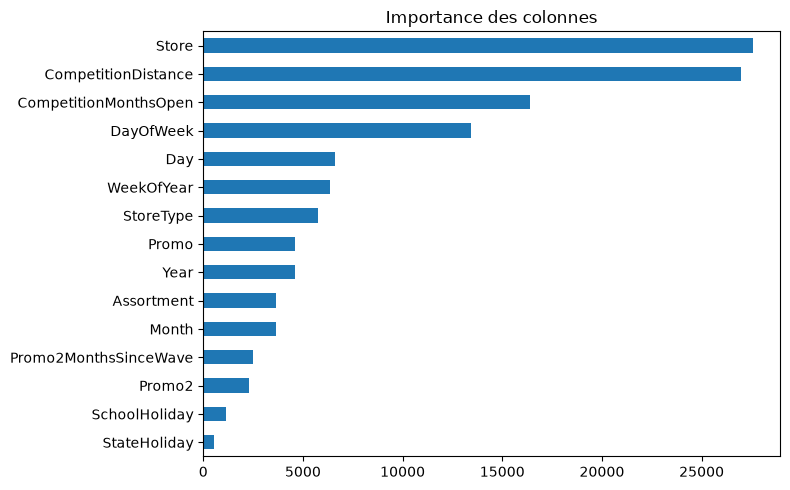

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

imp = pd.Series(model2.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Importance des colonnes")
plt.tight_layout()
plt.show()

## Modèle final sur toutes les données

Le modèle retenu (v2) est réentraîné sur tout l'historique.

In [24]:
final_params = {"n_estimators": 1000, "learning_rate": 0.05, "num_leaves": 127, "random_state": 42}

final_model = lgb.LGBMRegressor(**final_params)
final_model.fit(df_model[features], np.log1p(df_model["Sales"]))

with mlflow.start_run(run_name="lgbm_final_toutes_donnees"):
    mlflow.log_params(final_params)
    mlflow.lightgbm.log_model(final_model, "model", registered_model_name="rossmann-lgbm-final")

print("Modèle final entraîné")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020609 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 895
[LightGBM] [Info] Number of data points in the train set: 844338, number of used features: 15
[LightGBM] [Info] Start training from score 8.757737


2026/10/11 21:20:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 21:21:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modèle final entraîné


Registered model 'rossmann-lgbm-final' already exists. Creating a new version of this model...
Created version '3' of model 'rossmann-lgbm-final'.


## Prédictions sur test.csv

In [25]:
# Jointure avec les infos des magasins
test = pd.read_csv("../data/raw/test.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
test = test.merge(store, on="Store", how="left")
test["Open"] = test["Open"].fillna(1)

In [26]:
test["Year"] = test["Date"].dt.year
test["Month"] = test["Date"].dt.month
test["Day"] = test["Date"].dt.day
test["WeekOfYear"] = test["Date"].dt.isocalendar().week.astype(int)

test["StateHoliday"] = test["StateHoliday"].astype(str).map(mappings["StateHoliday"])
for col in ["StoreType", "Assortment"]:
    if not pd.api.types.is_numeric_dtype(test[col]):
        test[col] = test[col].map(mappings[col])

test["CompetitionMonthsOpen"] = (
    12 * (test["Year"] - test["CompetitionOpenSinceYear"])
    + (test["Month"] - test["CompetitionOpenSinceMonth"])
).clip(lower=0)

test["Promo2MonthsSinceWave"] = np.nan
for interval, months in interval_months.items():
    mask = test["PromoInterval"] == interval
    gaps = np.column_stack([(test.loc[mask, "Month"] - m) % 12 for m in months])
    test.loc[mask, "Promo2MonthsSinceWave"] = gaps.min(axis=1)

weeks_since_start = (
    52 * (test["Year"] - test["Promo2SinceYear"])
    + (test["WeekOfYear"] - test["Promo2SinceWeek"])
)
test.loc[weeks_since_start < 0, "Promo2MonthsSinceWave"] = np.nan

for c in ["CompetitionDistance", "CompetitionMonthsOpen"]:
    test[c] = test[c].astype("float64")

test_open = test[test["Open"] == 1].copy()

print(len(test), len(test_open))
print(test_open[features].isna().sum())

41088 35104
Store                        0
DayOfWeek                    0
Promo                        0
SchoolHoliday                0
StateHoliday                 0
Year                         0
Month                        0
Day                          0
WeekOfYear                   0
StoreType                    0
Assortment                   0
CompetitionDistance         76
CompetitionMonthsOpen    13014
Promo2                       0
Promo2MonthsSinceWave    18547
dtype: int64


In [27]:
test["Sales"] = 0.0
test.loc[test_open.index, "Sales"] = np.expm1(final_model.predict(test_open[features]))

submission = test[["Id", "Sales"]]
assert len(submission) == len(test)
assert submission["Sales"].notna().all()
assert (submission["Sales"] >= 0).all()
submission.to_csv("submission.csv", index=False)
print(submission.head(), len(submission))
print(test.loc[test_open.index, "Sales"].describe())

   Id        Sales
0   1  4191.928770
1   2  7627.797978
2   3  9210.688409
3   4  6488.131346
4   5  7083.161418 41088
count    35104.000000
mean      6839.329459
std       2552.963671
min       1238.793782
25%       5111.739112
50%       6386.497065
75%       8026.012944
max      25902.100526
Name: Sales, dtype: float64


Les prédictions sont aussi enregistrées dans MLflow

In [28]:
with mlflow.start_run(run_name="predictions_test"):
    mlflow.log_params(final_params)
    mlflow.log_metric("rmspe_validation", score2)  
    mlflow.log_metric("nb_magasins_fermes", int((test["Open"] == 0).sum()))
    mlflow.log_metric("ventes_moyennes_predites", float(test.loc[test_open.index, "Sales"].mean()))
    mlflow.log_artifact("submission.csv")